# Credit Risk

32k+ rows of data

[Dataset Source](https://www.kaggle.com/datasets/laotse/credit-risk-dataset/data)

#### 🎯 Objectives
* Train a model that can predict whether a client will default on a current loan.
* Evaluate the variables that most lend to a client defaulting - SHAP


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from helper import *
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.experimental import enable_iterative_imputer 
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (FunctionTransformer, StandardScaler,
                                   OrdinalEncoder, OneHotEncoder)
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier




sns.set_style("darkgrid")
sns.set_theme(
    "notebook",
    rc={
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "figure.titlesize": 16,
        "figure.titleweight": "bold",
    },
)
sns.set_palette(["mediumseagreen", "indianred"])

## 1. Importing

In [2]:
df_import = pd.read_csv("data/credit_risk_dataset.csv")
df = df_import.copy()
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
df.shape

(32581, 12)

## Data Audit & Cleaning

Styling & naming choice improvements:
* removing "`person_`" prefix from variable names
* Clarifying and/or shortening variable names
    * "`emp_length`": "`employment_length`", "`cb_default_on_file`": "`historical_default`"
* Mapping "Y" / "N" to 0 or 1
* Moving history of default `historical_default` to 2nd last column; and
* Moving target variable `loan_status` to last column

In [4]:
df = df.rename(columns=lambda col: col.replace("person_", ""))

df = df.rename(columns={
    "home_ownership": "ownership_type",
    "emp_length": "employment_length",
    "loan_amnt": "loan_amt",
    "loan_percent_income": "loan_pct_income",
    "cb_default_on_file": "historical_default",
    "cb_cred_hist_length": "cred_history_length"
})

df["historical_default"] = df["historical_default"].map({"N": 0, "Y": 1})

columns = [col for col in df.columns if col not in ["employment_length", "historical_default", "loan_status"]]
columns.insert(2, "employment_length")
columns += ["historical_default", "loan_status"]
df = df[columns]
df.head()

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status
0,22,59000,123.0,RENT,PERSONAL,D,35000,16.02,0.59,3,1,1
1,21,9600,5.0,OWN,EDUCATION,B,1000,11.14,0.10,2,0,0
2,25,9600,1.0,MORTGAGE,MEDICAL,C,5500,12.87,0.57,3,0,1
3,23,65500,4.0,RENT,MEDICAL,C,35000,15.23,0.53,2,0,1
4,24,54400,8.0,RENT,MEDICAL,C,35000,14.27,0.55,4,1,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  32581 non-null  int64  
 1   income               32581 non-null  int64  
 2   employment_length    31686 non-null  float64
 3   ownership_type       32581 non-null  str    
 4   loan_intent          32581 non-null  str    
 5   loan_grade           32581 non-null  str    
 6   loan_amt             32581 non-null  int64  
 7   loan_int_rate        29465 non-null  float64
 8   loan_pct_income      32581 non-null  float64
 9   cred_history_length  32581 non-null  int64  
 10  historical_default   32581 non-null  int64  
 11  loan_status          32581 non-null  int64  
dtypes: float64(3), int64(6), str(3)
memory usage: 3.0 MB


Feature Name	Description
person_age	Age
person_income	Annual Income
person_home_ownership	Home ownership
person_emp_length	Employment length (in years)
loan_intent	Loan intent
loan_grade	Loan grade
loan_amnt	Loan amount
loan_int_rate	Interest rate
loan_status	Loan status (0 is non default 1 is default)
loan_percent_income	Percent income
cb_person_default_on_file	Historical default
cb_preson_cred_hist_length	Credit history length

#### Nulls & Duplicates

In [6]:
df.isna().sum()[df.isna().sum() > 0]

employment_length     895
loan_int_rate        3116
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(165)

⚠️ The dataset contains null values and duplicate records.
- Null values: Will later be addressed during the preprocessing stage.
- Duplicate records: Will now be investigated further to determine whether removal is necessary:

In [8]:
df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()).head(10)

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status
15944,21,8088,NaN,RENT,MEDICAL,C,1200,15.23,0.15,2,1,0
16835,21,8088,NaN,RENT,MEDICAL,C,1200,15.23,0.15,2,1,0
2431,21,15600,0.0,RENT,MEDICAL,A,2800,7.40,0.18,4,0,1
17758,21,15600,0.0,RENT,MEDICAL,A,2800,7.40,0.18,4,0,1
2498,21,18000,0.0,RENT,DEBTCONSOLIDATION,A,3000,7.90,0.17,2,0,1
17601,21,18000,0.0,RENT,DEBTCONSOLIDATION,A,3000,7.90,0.17,2,0,1
1778,21,20000,0.0,RENT,MEDICAL,A,2000,NaN,0.10,3,0,0
17642,21,20000,0.0,RENT,MEDICAL,A,2000,NaN,0.10,3,0,0
740,21,21600,NaN,OWN,VENTURE,A,7125,6.99,0.33,3,0,0
17283,21,21600,NaN,OWN,VENTURE,A,7125,6.99,0.33,3,0,0


* These duplicate rows show the same data, but could be different individuals and valid observations, especially given the limited granularity of the variables and the absence of a unique identifier. (It is plausible that people with the same age, income, loan type, etc. show as duplicates but are in fact different individuals.) 

* They do not appear to result from data integrity or encoding issues, such as consecutive records being duplicated due as observed by the disparity in index.

> There is insufficient evidence to classify these records as actual duplicates. Therefore, they will be **retained to avoid unintentionally removing valid observations.**

In [9]:
cat_cols = ["ownership_type", "loan_intent", "loan_grade"]

target_col = ["loan_status"]

num_cols = df.select_dtypes(include="number").columns.drop(target_col, errors="ignore").tolist()

Categorical Columns 

In [10]:
for col in cat_cols:
    print(f"{df[col].value_counts()}\n")

ownership_type
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64



In [11]:
df["loan_intent"] = df["loan_intent"].replace({
    "DEBTCONSOLIDATION": "DEBT CONSOLIDATION",
    "HOMEIMPROVEMENT": "HOME IMPROVEMENT"
})

✅ No data integrity issues seem to be in our 3 categorical string columns. No spelling or input errors except missing spaces for readability

In [12]:
grade_map = {g: i for i, g in enumerate("ABCDEFG", start = 1)}
df["loan_grade_num"] = df["loan_grade"].map(grade_map)

#### Numerical Columns

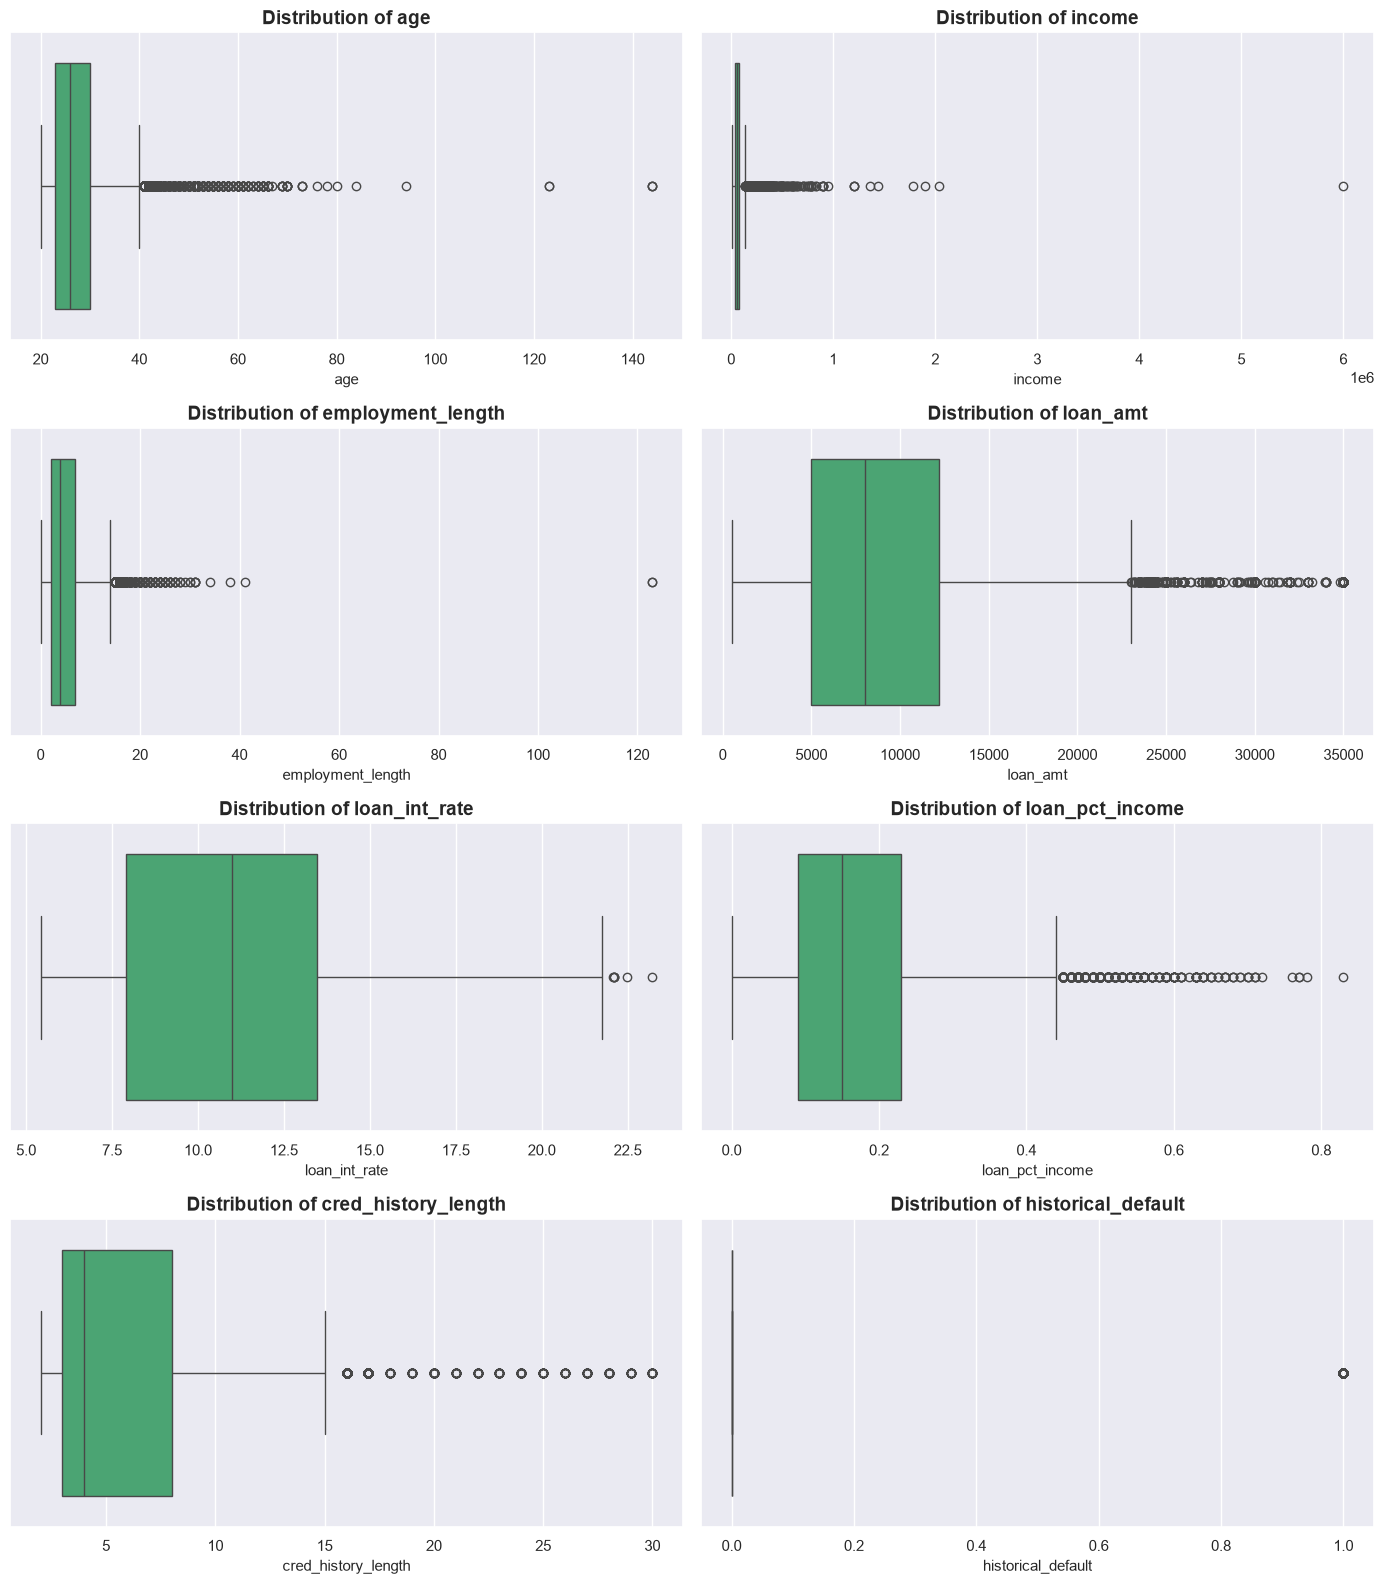

In [13]:
fig, axes = plt.subplots(
    nrows=math.ceil(len(num_cols) / 2),
    ncols=2,
    figsize=(14, 4 * math.ceil(len(num_cols) / 2))
)

axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")

for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

✅ No negative values  
✅ Adult ages  

⚠️ Extreme Outliers: There are extreme, and unlikely, outlier values in `age` and `employment_length` which will need to be observed and addressed. 

Outliers in Loan values: Outliers in other numerical features in the loan data, will be **retained** as potentially valid observations, as they may **represent high-value borrowers or larger loan amounts which we want to be able to observe and understand**, and all are relevant to the credit risk analysis.

In [14]:
df.nlargest(10, "age")

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num
81,144,250000,4.0,RENT,VENTURE,C,4800,13.57,0.02,3,0,0,3
183,144,200000,4.0,MORTGAGE,EDUCATION,B,6000,11.86,0.03,2,0,0,2
32297,144,6000000,12.0,MORTGAGE,PERSONAL,C,5000,12.73,0.00,25,0,0,3
575,123,80004,2.0,RENT,EDUCATION,B,20400,10.25,0.25,3,0,0,2
747,123,78000,7.0,RENT,VENTURE,B,20000,NaN,0.26,4,0,0,2
32416,94,24000,1.0,RENT,MEDICAL,C,6500,NaN,0.27,27,0,0,3
32506,84,94800,2.0,MORTGAGE,PERSONAL,A,10000,7.51,0.11,24,0,0,1
32422,80,64000,7.0,RENT,MEDICAL,B,6800,11.71,0.11,25,0,0,2
32355,78,48000,41.0,RENT,MEDICAL,A,3000,7.51,0.06,25,0,0,1
32534,76,75000,23.0,RENT,MEDICAL,A,15000,8.94,0.20,25,0,0,1


In [15]:
df.nlargest(5, "employment_length")

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num
0,22,59000,123.0,RENT,PERSONAL,D,35000,16.02,0.59,3,1,1,4
210,21,192000,123.0,MORTGAGE,VENTURE,A,20000,6.54,0.10,4,0,0,1
32355,78,48000,41.0,RENT,MEDICAL,A,3000,7.51,0.06,25,0,0,1
32515,53,106000,38.0,MORTGAGE,PERSONAL,B,20000,9.88,0.19,23,0,0,2
32428,58,49000,34.0,MORTGAGE,MEDICAL,D,7500,13.55,0.15,24,1,1,4


In [16]:
df.nlargest(10, "cred_history_length")

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num
32320,55,50000,2.0,RENT,HOME IMPROVEMENT,A,20000,7.51,0.40,30,0,1,1
32326,64,105000,8.0,RENT,HOME IMPROVEMENT,E,20000,18.64,0.19,30,0,0,5
32353,51,37200,4.0,RENT,MEDICAL,B,3000,10.62,0.08,30,0,1,2
32357,53,34000,0.0,MORTGAGE,MEDICAL,B,10000,10.39,0.29,30,0,1,2
32366,58,20000,0.0,RENT,EDUCATION,B,4000,9.99,0.20,30,0,0,2
32395,51,46560,2.0,MORTGAGE,PERSONAL,A,11600,8.94,0.25,30,0,0,1
32403,60,49008,5.0,OWN,PERSONAL,C,12000,13.79,0.24,30,1,0,3
32421,57,53000,1.0,MORTGAGE,PERSONAL,C,5800,13.16,0.11,30,1,0,3
32446,51,62046,8.0,RENT,VENTURE,A,8000,NaN,0.13,30,0,0,1
32448,52,83200,0.0,RENT,DEBT CONSOLIDATION,C,8000,15.96,0.10,30,1,0,3


In [17]:
df.nlargest(10, "income")

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num
32297,144,6000000,12.0,MORTGAGE,PERSONAL,C,5000,12.73,0.00,25,0,0,3
30049,42,2039784,0.0,RENT,VENTURE,C,8450,12.29,0.00,15,1,0,3
32546,60,1900000,5.0,MORTGAGE,PERSONAL,A,1500,NaN,0.00,21,0,0,1
32497,63,1782000,13.0,RENT,EDUCATION,C,12025,14.27,0.01,30,0,0,3
31924,44,1440000,7.0,MORTGAGE,DEBT CONSOLIDATION,A,6400,7.40,0.00,15,0,0,1
31922,47,1362000,9.0,MORTGAGE,VENTURE,A,6600,7.74,0.00,17,0,0,1
17833,32,1200000,1.0,MORTGAGE,VENTURE,A,12000,7.51,0.01,8,0,0,1
29119,36,1200000,16.0,OWN,MEDICAL,A,10000,6.54,0.01,11,0,0,1
29120,40,1200000,1.0,MORTGAGE,MEDICAL,A,10000,NaN,0.01,16,0,0,1
17834,34,948000,18.0,MORTGAGE,PERSONAL,B,2000,9.99,0.00,7,0,0,2


No age < cred hist limit

In [18]:
df[
    (df["cred_history_length"] > df["age"])
].sort_values("age", ascending=False)

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num


In [19]:
df[df["employment_length"] > df["age"] - 15]

,age,income,employment_length,ownership_type,loan_intent,loan_grade,loan_amt,loan_int_rate,loan_pct_income,cred_history_length,historical_default,loan_status,loan_grade_num
0,22,59000,123.0,RENT,PERSONAL,D,35000,16.02,0.59,3,1,1,4
210,21,192000,123.0,MORTGAGE,VENTURE,A,20000,6.54,0.10,4,0,0,1


Based on these extreme outliers that suggest data errors, **rules and data limits will be enforced:**
* Age <= 100
* Employment_length > age - 15 
    * Where employment_length is over = dealing with unlikely values like 123 years of employment

In [20]:
(df["age"] > 100).sum()

np.int64(5)

In [21]:
df = df.drop(
    df[
        (df["age"] > 100) |
        (df["employment_length"] > df["age"] - 15)
    ].index
)

## 📊 2. EDA

In [22]:
df.shape

(32574, 13)

In [23]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,32574.0,27.718426,6.204987,20.00,23.00,26.00,30.00,94.00
income,32574.0,65878.480813,52531.938809,4000.00,38500.00,55000.00,79200.00,2039784.00
employment_length,31679.0,4.782064,4.034948,0.00,2.00,4.00,7.00,41.00
loan_amt,32574.0,9588.018051,6320.249598,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29459.0,11.011529,3.240497,5.42,7.90,10.99,13.47,23.22
loan_pct_income,32574.0,0.170202,0.106755,0.00,0.09,0.15,0.23,0.83
cred_history_length,32574.0,5.804108,4.053873,2.00,3.00,4.00,8.00,30.00
historical_default,32574.0,0.176337,0.381112,0.00,0.00,0.00,0.00,1.00
loan_status,32574.0,0.218180,0.413017,0.00,0.00,0.00,0.00,1.00
loan_grade_num,32574.0,2.218149,1.166382,1.00,1.00,2.00,3.00,7.00


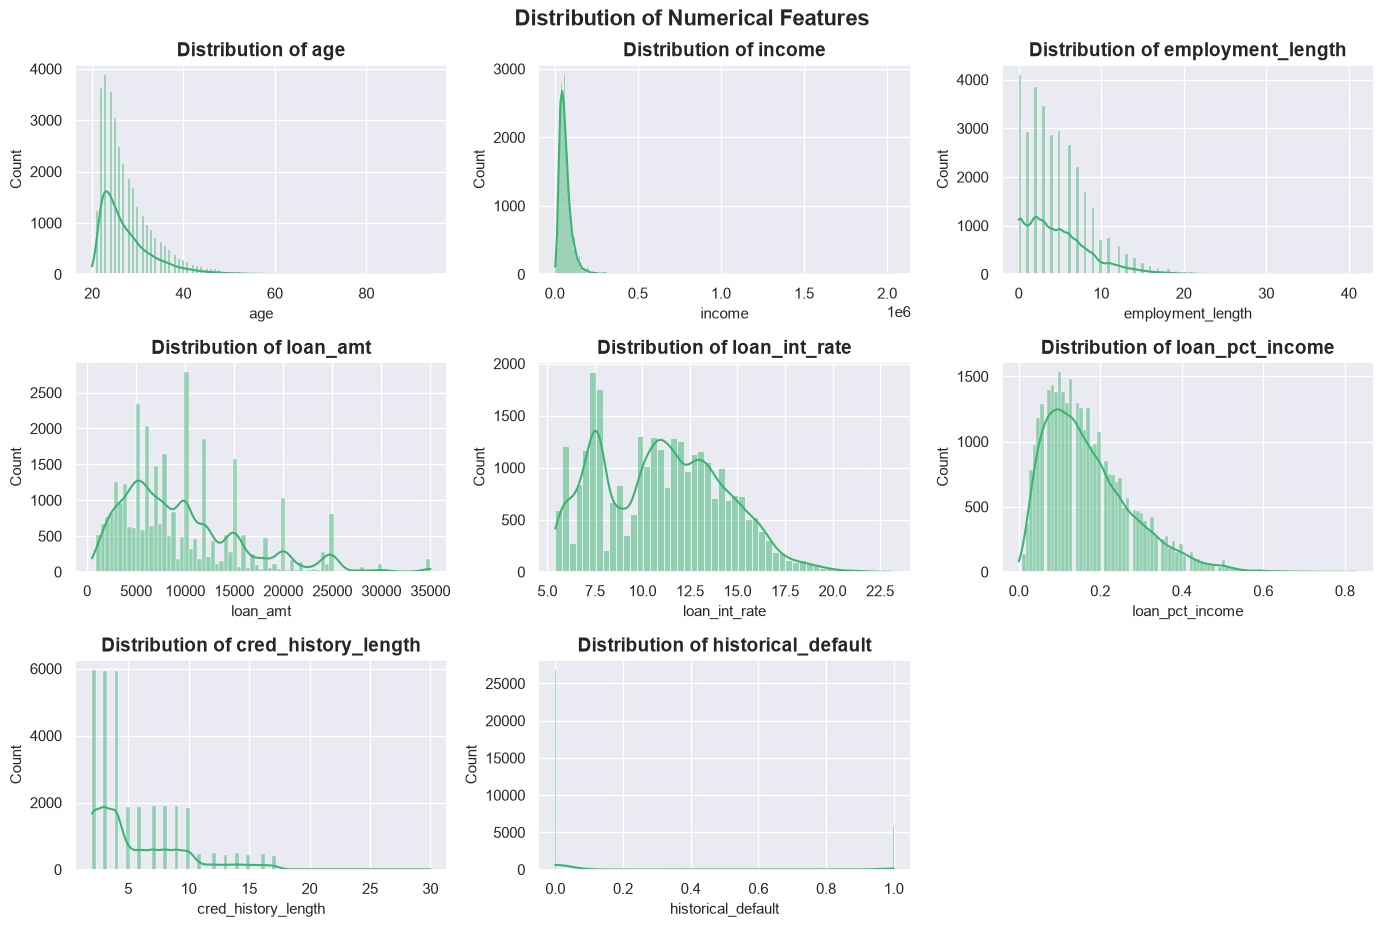

In [24]:
fig, axes = plt.subplots(
    nrows=math.ceil(len(num_cols) / 2),
    ncols=3,
    figsize=(14, 3 * math.ceil(len(num_cols) / 2))
)

axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True)
    axes[i].set_title(f"Distribution of {col}")

for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

All numerical variables are predominantly right-skewed

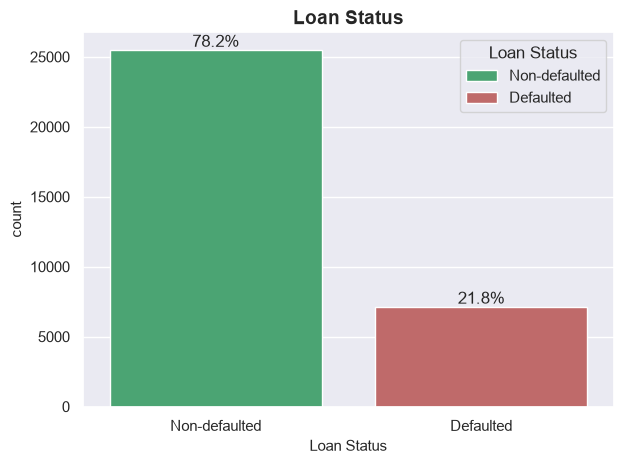

In [25]:
ax = sns.countplot(data=df, x="loan_status", hue="loan_status")

for bar in ax.patches:
    if bar.get_height() == 0:
        continue
    pct = bar.get_height() / len(df) * 100
    ax.annotate(f"{pct:.1f}%", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")

ax.set_xticks([0, 1])
ax.set_xticklabels(["Non-defaulted", "Defaulted"])
ax.set_xlabel("Loan Status")
ax.set_title("Loan Status")
ax.legend(title="Loan Status", labels=["Non-defaulted", "Defaulted"])
plt.tight_layout()
plt.show()

As expected, there is an imbalance with the data between 80% non-default and 20% defaulting clients. It is important to account for this moderate imbalance during modeling with techniques like stratifying the split.

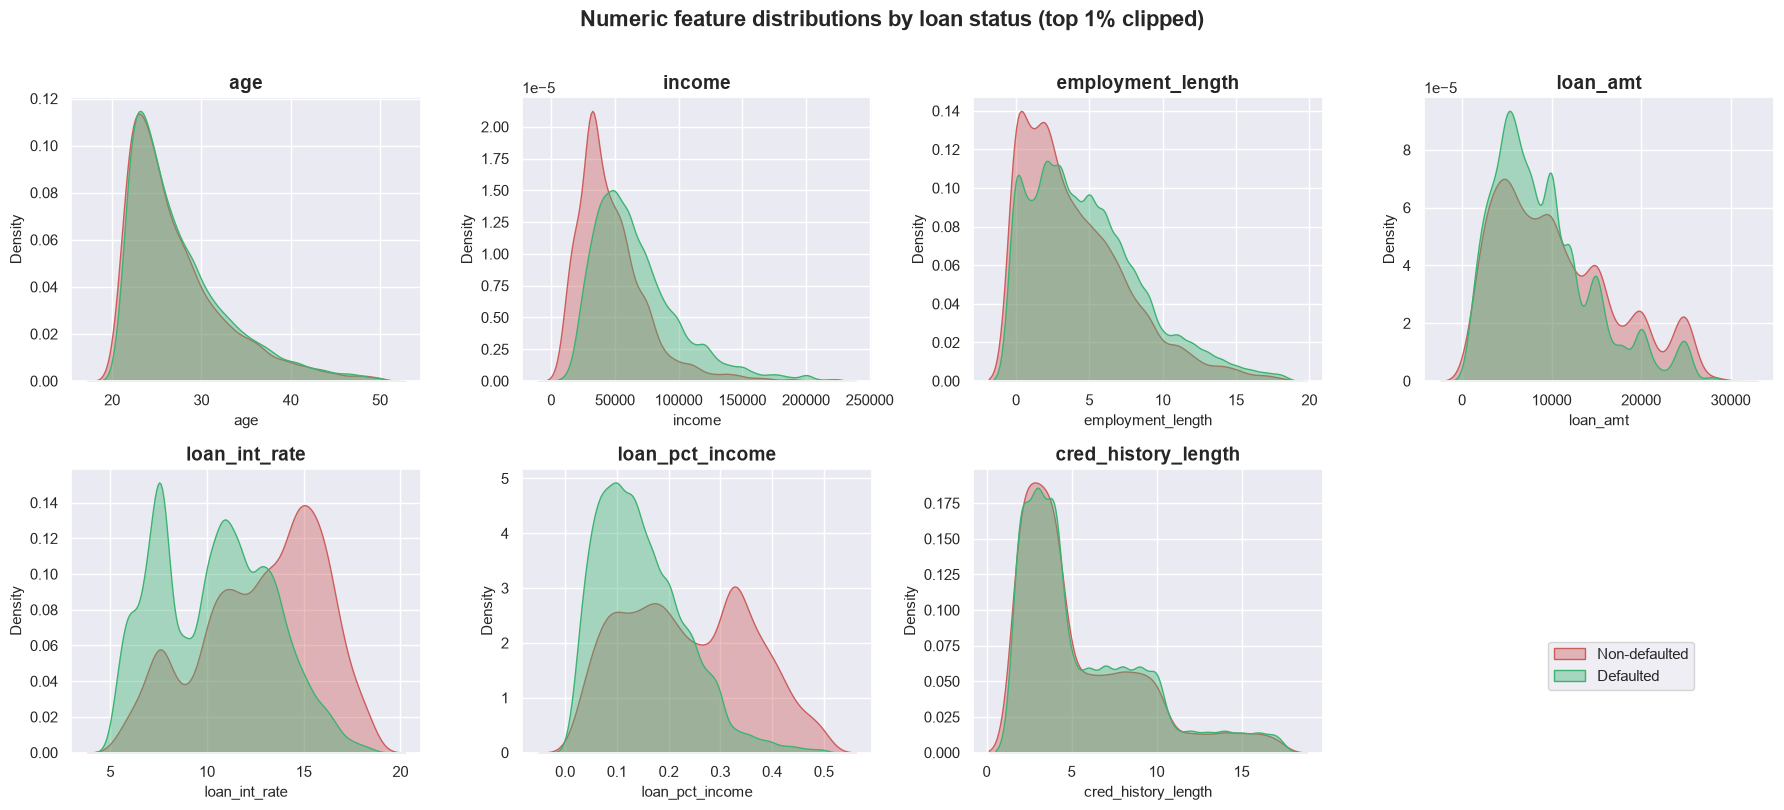

In [26]:
num_cols = ["age", "income", "employment_length", "loan_amt",
            "loan_int_rate", "loan_pct_income", "cred_history_length"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    # clip the top 1% so outliers (income 2M, age 94) don't squash the plot
    upper = df[col].quantile(0.99)
    sns.kdeplot(data=df[df[col] <= upper], x=col, hue="loan_status",
                common_norm=False, fill=True, alpha=0.4, ax=ax, legend=False)
    ax.set_title(col)

axes[-1].axis("off")  # unused 8th panel
fig.legend(["Non-defaulted", "Defaulted"], loc="lower right", bbox_to_anchor=(0.95, 0.15))
plt.suptitle("Numeric feature distributions by loan status (top 1% clipped)", y=1.01)
plt.tight_layout()
plt.show()

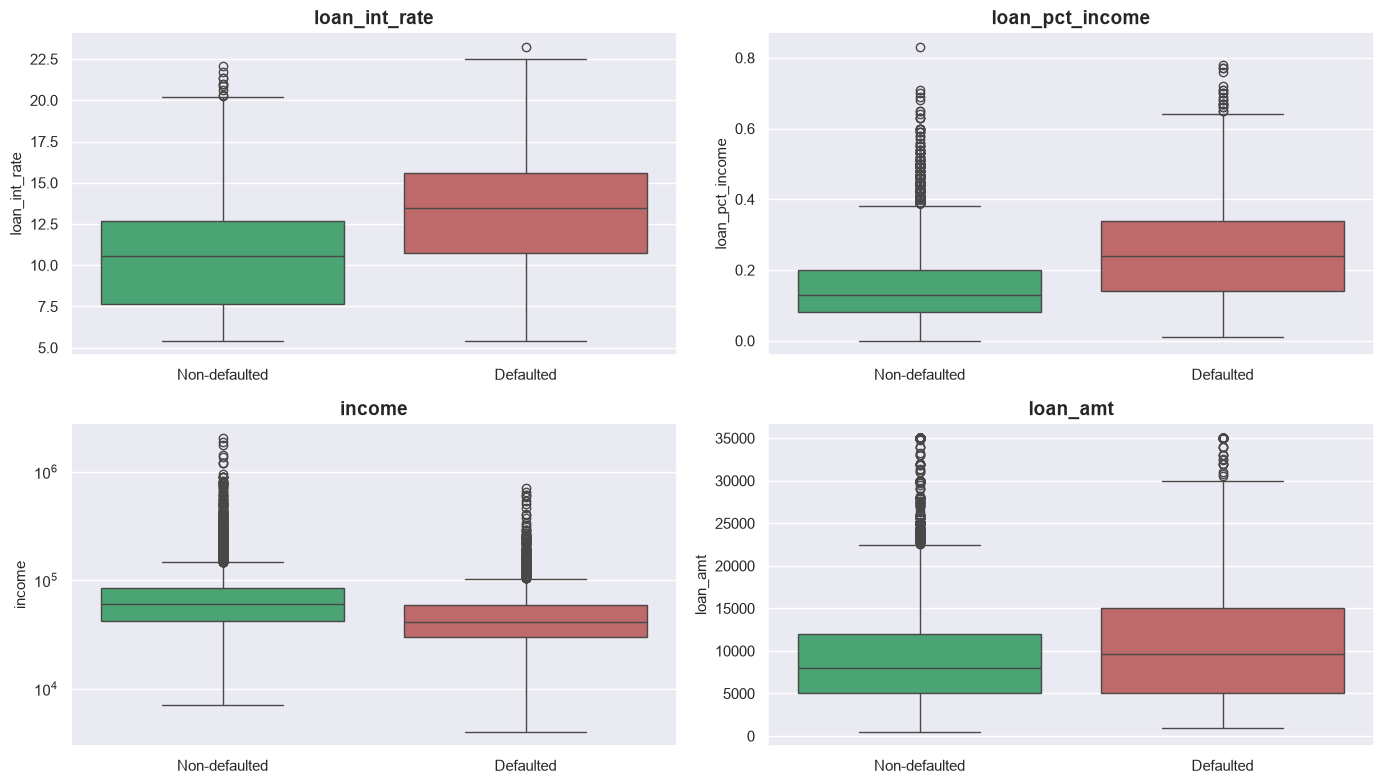

In [27]:
key_cols = ["loan_int_rate", "loan_pct_income", "income", "loan_amt"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, col in zip(axes, key_cols):
    sns.boxplot(data=df, x="loan_status", y=col, hue="loan_status", legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non-defaulted", "Defaulted"])
    ax.set_xlabel("")
    ax.set_title(col)

axes[2].set_yscale("log")  # income is heavily right-skewed
plt.tight_layout()
plt.show()

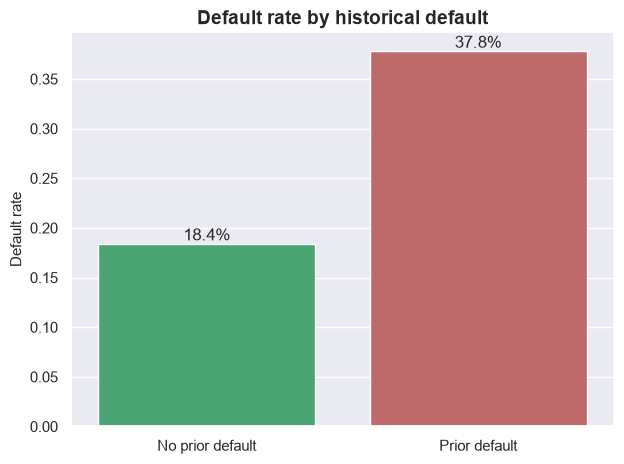

In [28]:
ax = sns.barplot(data=df, x="historical_default", y="loan_status",
                 hue="historical_default", legend=False, errorbar=None)

for bar in ax.patches:
    ax.annotate(f"{bar.get_height() * 100:.1f}%",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")

ax.set_xticks([0, 1])
ax.set_xticklabels(["No prior default", "Prior default"])
ax.set_xlabel("")
ax.set_ylabel("Default rate")
ax.set_title("Default rate by historical default")
plt.tight_layout()
plt.show()

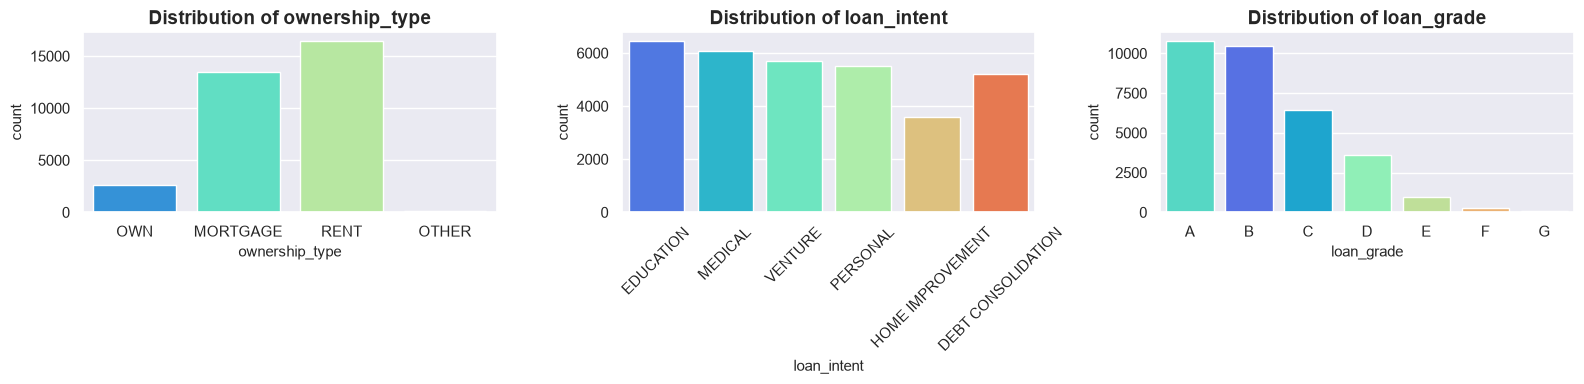

In [29]:
cat_cols = df.select_dtypes(include=["object", "str", "category"]).columns.tolist()

fig, axes = plt.subplots(
    nrows=math.ceil(len(cat_cols) / 3),
    ncols=3,
    figsize=(16, 4 * math.ceil(len(cat_cols) / 3))
)

axes = axes.flatten()

for i, col in enumerate(cat_cols):
    order = list("ABCDEFG") if col == "loan_grade" else None

    sns.countplot(
        data=df, x=col, ax=axes[i],
        order=order, palette="rainbow", hue=col, legend=False
    )
    axes[i].set_title(f"Distribution of {col}")

    if col == "loan_intent":
        axes[i].tick_params(axis="x", rotation=45)

for i in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

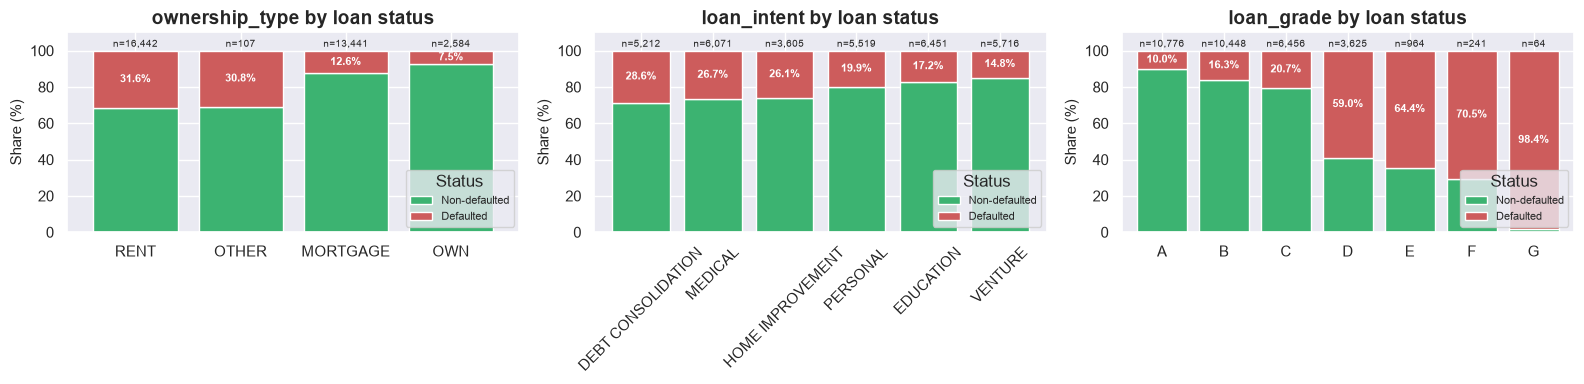

In [30]:
n_rows = math.ceil(len(cat_cols) / 3)

fig, axes = plt.subplots(n_rows, 3, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    ct = pd.crosstab(df[col], df["loan_status"], normalize="index") * 100
    counts = df[col].value_counts()

    if col == "loan_grade":
        ct = ct.sort_index()
    else:
        ct = ct.sort_values(1, ascending=False)  # highest default rate first

    ct.plot(kind="bar", stacked=True, ax=ax, color=["mediumseagreen", "indianred"], width=0.8)

    # label the default segment (and n) on each bar
    for i, idx in enumerate(ct.index):
        ax.text(i, ct.loc[idx, 0] + ct.loc[idx, 1] / 2, f"{ct.loc[idx, 1]:.1f}%",
                ha="center", va="center", color="white", fontsize=8, fontweight="bold")
        ax.text(i, 101, f"n={counts[idx]:,}", ha="center", va="bottom", fontsize=7)

    ax.set_title(f"{col} by loan status")
    ax.set_xlabel("")
    ax.set_ylabel("Share (%)")
    ax.set_ylim(0, 110)
    ax.legend(title="Status", labels=["Non-defaulted", "Defaulted"], fontsize=8, loc="lower right")
    ax.tick_params(axis="x", rotation=45 if col == "loan_intent" else 0)

for ax in axes[len(cat_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

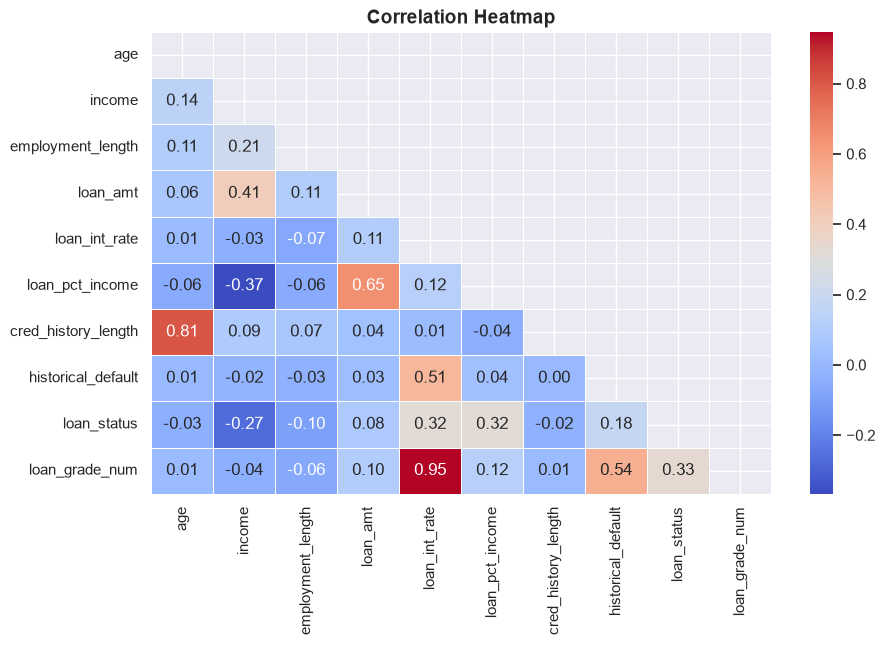

In [31]:
num_features = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))

corr = num_features.corr(method="spearman")
matrix = np.triu(corr)

sns.heatmap(corr, mask=matrix, cmap="coolwarm", annot=True, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

Check for multicollinearity concerns later after scaling our inputs.

## Modeling

Stratifying into 70/15/15

In [32]:
X = df.drop(columns=["loan_status", "loan_grade"])
y = df["loan_status"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

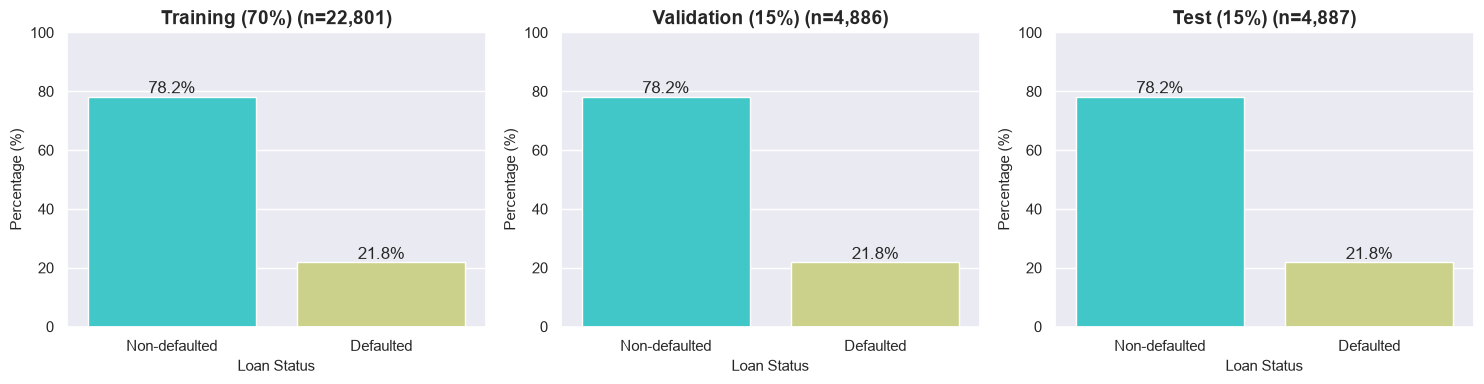

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, split, title in zip(
    axes,
    [y_train, y_val, y_test],
    ["Training (70%)", "Validation (15%)", "Test (15%)"]
):
    percentages = split.value_counts(normalize=True).sort_index() * 100

    sns.barplot(
        x=percentages.index,
        y=percentages.values,
        ax=ax,
        hue=percentages.index,
        palette="rainbow",
        legend=False
    )

    for bar in ax.patches:
        ax.annotate(
            f"{bar.get_height():.1f}%",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom"
        )

    ax.set_title(f"{title} (n={len(split):,})")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non-defaulted", "Defaulted"])
    ax.set_xlabel("Loan Status")
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

In [34]:
X.columns

Index(['age', 'income', 'employment_length', 'ownership_type', 'loan_intent',
       'loan_amt', 'loan_int_rate', 'loan_pct_income', 'cred_history_length',
       'historical_default', 'loan_grade_num'],
      dtype='str')

In [35]:
num_cols = df.select_dtypes(include="number").columns.drop(target_col, errors="ignore").tolist()
num_cols

['age',
 'income',
 'employment_length',
 'loan_amt',
 'loan_int_rate',
 'loan_pct_income',
 'cred_history_length',
 'historical_default',
 'loan_grade_num']

In [36]:
skew = X_train[num_cols].skew().sort_values(ascending=False)

skew_df = pd.DataFrame({
    "skew": skew.map("{:.2f}".format),
    "> 1": skew.abs() > 1
})
print(skew_df)

                     skew    > 1
income               8.08   True
age                  1.96   True
historical_default   1.69   True
cred_history_length  1.67   True
employment_length    1.24   True
loan_amt             1.21   True
loan_pct_income      1.07   True
loan_grade_num       0.86  False
loan_int_rate        0.20  False


In [37]:
from sklearn.preprocessing import PowerTransformer

num_cols = ["age", "income", "employment_length", "loan_amt",
            "loan_int_rate", "loan_pct_income", "cred_history_length"]

# before
before = X_train[num_cols].skew()

# after log1p
after_log = np.log1p(X_train[num_cols]).skew()

# after Yeo-Johnson (NaNs are ignored when fitting and left as NaN)
pt = PowerTransformer(method="yeo-johnson", standardize=False)
yj = pd.DataFrame(pt.fit_transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
after_yj = yj.skew()

skew_df = pd.DataFrame({
    "before": before,
    "log1p": after_log,
    "yeo-johnson": after_yj,
    "lambda": pt.lambdas_,
}).sort_values("before", ascending=False)

print(skew_df.round(2))

                     before  log1p  yeo-johnson  lambda
income                 8.08   0.14        -0.01   -0.06
age                    1.96   1.18         0.16   -2.53
cred_history_length    1.67   0.49         0.10   -0.51
employment_length      1.24  -0.46        -0.05    0.27
loan_amt               1.21  -0.44        -0.02    0.23
loan_pct_income        1.07   0.82         0.09   -3.85
loan_int_rate          0.20  -0.27        -0.04    0.50


#### 🔧 Preprocessing Pipeline

1. Categorical Features
    * Nominal: `ownership_type`, `loan_intent`
        * Chosen Imputer: SimpleImputer(strategy="constant", fill_value="Missing") - missing data will be kept as a true unknown 
        * Chosen Encoder: OneHotEncoder(drop="first", handle_unknown="ignore") - one-hot encoding preserves the absence of an order between types
2. Numerical Features
    * Correlated Age Variables: `age`, `employment_length`, `cred_history_length`
        * Chosen Imputer: IterativeImputer - Captures directional relationships between variables (like age and credit history length), making use of where related data is complete to impute the missing correlated data in a round robin fashion.
        * Chosen Transformer: log1p + StandardScaler - helps address predominantly skewed variables
    * Correlated Loan Rate + Grade Variable: `loan_int_rate` & `loan_grade_num`
        * Chosen Imputer: IterativeImputer
        * Chosen Transformer: StandardScaler only - lower skew values < 1
    * Other Num Features: `income`, `loan_pct_income`, `loan_amt`
        * Chosen Imputer: Median - robust to outliers
        * Chosen Transformer: log1p + StandardScaler - helps address predominantly skewed variables

`historical_default` passes through since it's already 0/1

In [38]:
# # map grade A-G -> 1-7 before the pipeline (fixed rule, no leakage)
# grade_map = {g: i for i, g in enumerate("ABCDEFG", start=1)}
# for d in (X_train, X_val, X_test):
#     d["loan_grade_num"] = d["loan_grade"].map(grade_map)

def log1p_func(X):
    return np.log1p(X)

def make_log():
    return FunctionTransformer(log1p_func, feature_names_out="one-to-one")

cat_cols = ["ownership_type", "loan_intent"]
age_cols     = ["age", "employment_length", "cred_history_length"]
rate_cols    = ["loan_int_rate", "loan_grade_num"]
other_num_cols   = ["income", "loan_pct_income", "loan_amt"]
bin_cols       = ["historical_default"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
        ]), cat_cols),

        ("num_ages", Pipeline([
            ("imputer", IterativeImputer(max_iter=10, random_state=42)),
            ("fallback", SimpleImputer(strategy="median")),
            ("log", make_log()),
            ("scaler", StandardScaler()),
        ]), age_cols),

        ("num_rates", Pipeline([
            ("imputer", IterativeImputer(max_iter=10, random_state=42)),
            ("fallback", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), rate_cols),

        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("log", make_log()),
            ("scaler", StandardScaler()),
        ]), other_num_cols),

        ("bi", SimpleImputer(strategy="most_frequent"), bin_cols),
    ],
    remainder="drop",
)

preprocessor.set_output(transform="pandas")

X_train_p = preprocessor.fit_transform(X_train)
X_val_p   = preprocessor.transform(X_val)
X_test_p  = preprocessor.transform(X_test)

#### VIF / Multicollinearity check

If there are highly multicollinear variables, there is possibly a need for more preprocessing as these can distort model estimates (inflated sensitivity and high variance). Multicollinearity can be computed via Variance Inflation Factor:  
* VIF values > 5 indicates moderate multicollinearity through inflated factors
* VIF > 10 indicates extreme multicollinearity

In [39]:
X_const = add_constant(X_train_p.astype(float))

vif = pd.DataFrame({
    "feature": X_train_p.columns,
    "VIF": [variance_inflation_factor(X_const.values, i + 1)
            for i in range(X_train_p.shape[1])]
}).sort_values("VIF", ascending=False)

vif["VIF"] = vif["VIF"].round(2)
vif["> 5"] = vif["VIF"] > 5
print(vif)

                              feature   VIF    > 5
12          num_rates__loan_grade_num  8.93   True
11           num_rates__loan_int_rate  8.54   True
15                      num__loan_amt  7.93   True
14               num__loan_pct_income  7.73   True
13                        num__income  5.95   True
8                       num_ages__age  3.53  False
10      num_ages__cred_history_length  3.48  False
3          cat__loan_intent_EDUCATION  1.82  False
7            cat__loan_intent_VENTURE  1.78  False
5            cat__loan_intent_MEDICAL  1.78  False
6           cat__loan_intent_PERSONAL  1.73  False
4   cat__loan_intent_HOME IMPROVEMENT  1.53  False
16             bi__historical_default  1.41  False
2            cat__ownership_type_RENT  1.30  False
1             cat__ownership_type_OWN  1.17  False
9         num_ages__employment_length  1.08  False
0           cat__ownership_type_OTHER  1.01  False


#### Baseline model

In [40]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_p, y_train)

results, new_results = score_predictions(
    dummy.predict_proba(X_train_p)[:, 1],
    dummy.predict_proba(X_val_p)[:, 1],
    y_train, y_val,
    "Baseline Dummy", {"strategy": "most_frequent"},
)
new_results

,Model,Val PR-AUC,Val ROC-AUC,Train ROC-AUC,F1,Precision,Recall,Threshold,Params
0,Baseline Dummy,0.218,0.5,0.5,0.0,0.0,0.0,0.5,{'strategy': 'most_frequent'}


In [41]:
logreg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42,
)
logreg.fit(X_train_p, y_train)

proba_train = logreg.predict_proba(X_train_p)[:, 1]
proba_val = logreg.predict_proba(X_val_p)[:, 1]

results, new_results = score_predictions(
    proba_train, proba_val,
    y_train, y_val,
    "Baseline Logistic Regression", {"class_weight": "balanced", "max_iter": 1000},
    results=results,
)
new_results

,Model,Val PR-AUC,Val ROC-AUC,Train ROC-AUC,F1,Precision,Recall,Threshold,Params
0,Baseline Logistic Regression,0.705,0.868,0.876,0.62,0.511,0.789,0.5,"{'class_weight': 'balanced', 'max_iter': 1000}"
1,Baseline Dummy,0.218,0.500,0.500,0.00,0.000,0.000,0.5,{'strategy': 'most_frequent'}


In [42]:
lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=3.6,
    random_state=42,
    verbose=-1,
)
lgbm.fit(
    X_train_p, y_train,
    eval_set=[(X_val_p, y_val)],
    eval_metric="average_precision",
)

results, new_results = score_predictions(
    lgbm.predict_proba(X_train_p)[:, 1],
    lgbm.predict_proba(X_val_p)[:, 1],
    y_train, y_val,
    "LightGBM", {"n_estimators": 500, "lr": 0.05, "num_leaves": 31},
    results=results,
)
new_results

c:\Users\giddy\Desktop\projects\credit-risk\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,Model,Val PR-AUC,Val ROC-AUC,Train ROC-AUC,F1,Precision,Recall,Threshold,Params
0,LightGBM,0.902,0.946,0.993,0.81,0.824,0.797,0.5,"{'n_estimators': 500, 'lr': 0.05, 'num_leaves'..."
1,Baseline Logistic Regression,0.705,0.868,0.876,0.62,0.511,0.789,0.5,"{'class_weight': 'balanced', 'max_iter': 1000}"
2,Baseline Dummy,0.218,0.500,0.500,0.00,0.000,0.000,0.5,{'strategy': 'most_frequent'}


In [43]:
xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=3.6,          # ~78/22, drop this if you skip weighting
    eval_metric="aucpr",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
)
xgb.fit(
    X_train_p, y_train,
    eval_set=[(X_val_p, y_val)],
    verbose=False,
)

results, new_results = score_predictions(
    xgb.predict_proba(X_train_p)[:, 1],
    xgb.predict_proba(X_val_p)[:, 1],
    y_train, y_val,
    "XGBoost", {"n_estimators": xgb.best_iteration + 1, "lr": 0.05, "max_depth": 5},
    results=results,
)
new_results

,Model,Val PR-AUC,Val ROC-AUC,Train ROC-AUC,F1,Precision,Recall,Threshold,Params
0,LightGBM,0.902,0.946,0.993,0.810,0.824,0.797,0.5,"{'n_estimators': 500, 'lr': 0.05, 'num_leaves'..."
1,XGBoost,0.899,0.946,0.982,0.799,0.799,0.799,0.5,"{'n_estimators': 494, 'lr': 0.05, 'max_depth': 5}"
2,Baseline Logistic Regression,0.705,0.868,0.876,0.620,0.511,0.789,0.5,"{'class_weight': 'balanced', 'max_iter': 1000}"
3,Baseline Dummy,0.218,0.500,0.500,0.000,0.000,0.000,0.5,{'strategy': 'most_frequent'}


In [44]:
cat = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    auto_class_weights="Balanced",   # remove to skip weighting
    eval_metric="PRAUC",
    early_stopping_rounds=50,
    random_seed=42,
    verbose=0,
)
cat.fit(
    X_train_p, y_train,
    eval_set=(X_val_p, y_val),
)

results, new_results = score_predictions(
    cat.predict_proba(X_train_p)[:, 1],
    cat.predict_proba(X_val_p)[:, 1],
    y_train, y_val,
    "CatBoost", {"iterations": cat.get_best_iteration() + 1, "lr": 0.05, "depth": 6},
    results=results,
)
new_results

,Model,Val PR-AUC,Val ROC-AUC,Train ROC-AUC,F1,Precision,Recall,Threshold,Params
0,LightGBM,0.902,0.946,0.993,0.810,0.824,0.797,0.5,"{'n_estimators': 500, 'lr': 0.05, 'num_leaves'..."
1,CatBoost,0.901,0.945,0.981,0.816,0.841,0.793,0.5,"{'iterations': 705, 'lr': 0.05, 'depth': 6}"
2,XGBoost,0.899,0.946,0.982,0.799,0.799,0.799,0.5,"{'n_estimators': 494, 'lr': 0.05, 'max_depth': 5}"
3,Baseline Logistic Regression,0.705,0.868,0.876,0.620,0.511,0.789,0.5,"{'class_weight': 'balanced', 'max_iter': 1000}"
4,Baseline Dummy,0.218,0.500,0.500,0.000,0.000,0.000,0.5,{'strategy': 'most_frequent'}


## Conclusion

* Threshold tuning
* Top n cases